# Лабораторная работа №1: регрессия
**Датасет:** Wine Quality (UCI) — красные и белые вина объединены, тип вина закодирован признаком `is_red`.
**Метрика:** RMSE (основная), MAE (дополнительная). Порог качества: RMSE < 0.70.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 1. Знакомство с данными

In [10]:
BASE = 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/'

def load(color):
    name = f'winequality-{color}.csv'
    src = name if Path(name).exists() else BASE + name
    d = pd.read_csv(src, sep=';')
    d['is_red'] = int(color == 'red')
    return d

df = pd.concat([load('red'), load('white')], ignore_index=True)
print(df.shape)
df.head()

(6497, 13)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality,is_red
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5,1
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5,1
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6,1
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5,1


In [11]:
df.info()
print('Пропуски:', df.isna().sum().sum())
print('Полных дубликатов:', df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6497 entries, 0 to 6496
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         6497 non-null   float64
 1   volatile acidity      6497 non-null   float64
 2   citric acid           6497 non-null   float64
 3   residual sugar        6497 non-null   float64
 4   chlorides             6497 non-null   float64
 5   free sulfur dioxide   6497 non-null   float64
 6   total sulfur dioxide  6497 non-null   float64
 7   density               6497 non-null   float64
 8   pH                    6497 non-null   float64
 9   sulphates             6497 non-null   float64
 10  alcohol               6497 non-null   float64
 11  quality               6497 non-null   int64  
 12  is_red                6497 non-null   int64  
dtypes: float64(11), int64(2)
memory usage: 660.0 KB
Пропуски: 0
Полных дубликатов: 1177


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215307,1.296434,3.80000,6.40000,7.00000,7.70000,15.90000
volatile acidity,6497.0,0.339666,0.164636,0.08000,0.23000,0.29000,0.40000,1.58000
citric acid,6497.0,0.318633,0.145318,0.00000,0.25000,0.31000,0.39000,1.66000
residual sugar,6497.0,5.443235,4.757804,0.60000,1.80000,3.00000,8.10000,65.80000
chlorides,6497.0,0.056034,0.035034,0.00900,0.03800,0.04700,0.06500,0.61100
free sulfur dioxide,6497.0,30.525319,17.749400,1.00000,17.00000,29.00000,41.00000,289.00000
total sulfur dioxide,6497.0,115.744574,56.521855,6.00000,77.00000,118.00000,156.00000,440.00000
density,6497.0,0.994697,0.002999,0.98711,0.99234,0.99489,0.99699,1.03898
pH,6497.0,3.218501,0.160787,2.72000,3.11000,3.21000,3.32000,4.01000
sulphates,6497.0,0.531268,0.148806,0.22000,0.43000,0.51000,0.60000,2.00000


In [13]:
df = df.drop_duplicates(keep='first')
df.shape

(5320, 13)

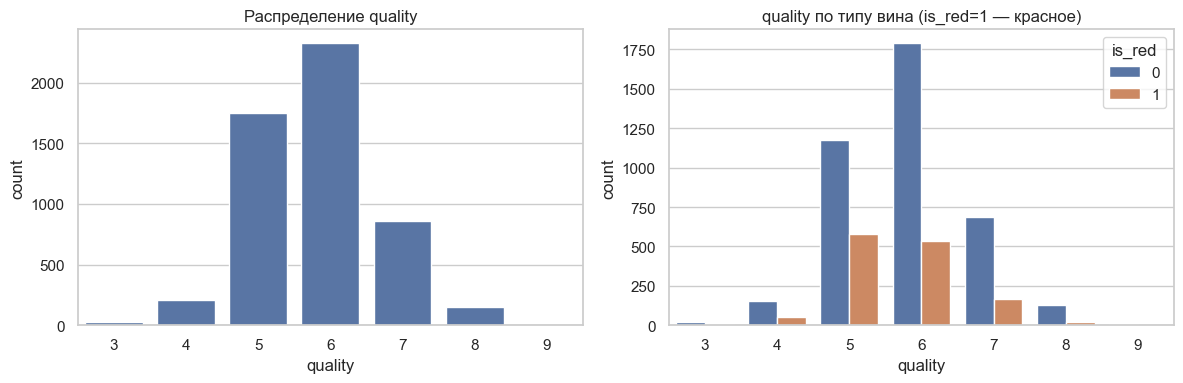

quality
3    0.0056
4    0.0387
5    0.3293
6    0.4367
7    0.1609
8    0.0278
9    0.0009
Name: proportion, dtype: float64
        count      mean       std
is_red                           
0        3961  5.854835  0.890683
1        1359  5.623252  0.823578


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='quality', ax=ax[0])
ax[0].set_title('Распределение quality')
sns.countplot(data=df, x='quality', hue='is_red', ax=ax[1])
ax[1].set_title('quality по типу вина (is_red=1 — красное)')
plt.tight_layout()
plt.show()

print(df['quality'].value_counts(normalize=True).sort_index().round(4))
print(df.groupby('is_red')['quality'].agg(['count', 'mean', 'std']))

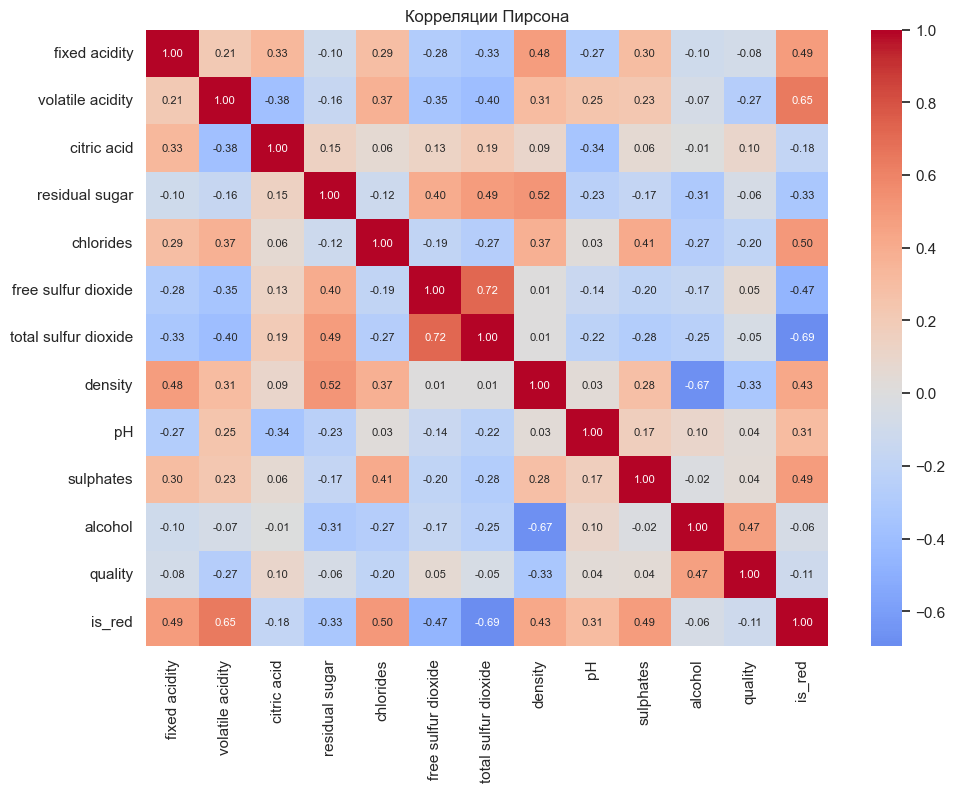

alcohol                 0.469422
density                -0.326434
volatile acidity       -0.265205
chlorides              -0.202137
is_red                 -0.114809
citric acid             0.097954
fixed acidity          -0.080092
residual sugar         -0.056830
free sulfur dioxide     0.054002
total sulfur dioxide   -0.050296
sulphates               0.041884
pH                      0.039733
Name: quality, dtype: float64

In [15]:
corr = df.corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, annot_kws={'size': 8})
plt.title('Корреляции Пирсона')
plt.show()

corr_q = corr['quality'].drop('quality').sort_values(key=abs, ascending=False)
corr_q

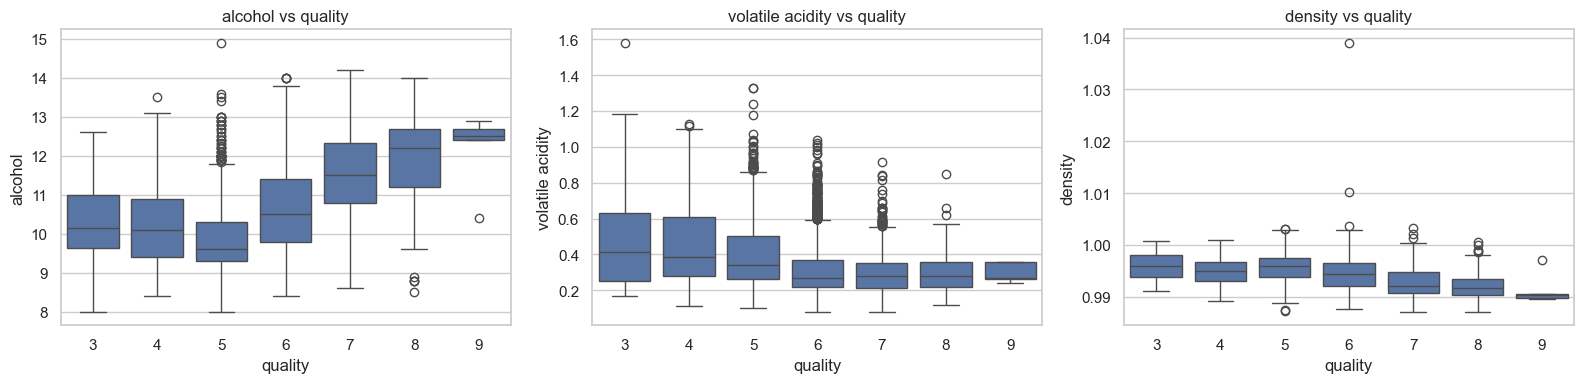

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, col in zip(ax, ['alcohol', 'volatile acidity', 'density']):
    sns.boxplot(data=df, x='quality', y=col, ax=a)
    a.set_title(f'{col} vs quality')
plt.tight_layout()
plt.show()

### Выводы по EDA
- **Распределение целевой переменной.** Оценки сконцентрированы вокруг 5–7, крайние значения (3, 4, 8, 9) редки. Это значит, что модель будет мало видеть примеров для крайних классов и, скорее всего, будет «стягивать» предсказания к середине.
- **alcohol** — признак с самой заметной положительной связью с `quality`: более крепкие вина в среднем получают более высокие оценки. Его однозначно стоит использовать в моделях.
- **volatile acidity** (летучая кислотность) связана с `quality` отрицательно: высокие значения дают неприятный уксусный привкус, и дегустаторы снижают оценку.
- **density** коррелирует с `quality` отрицательно, но во многом через сильную обратную связь с `alcohol` (и положительную с `residual sugar`). Это мультиколлинеарность: коэффициенты линейной модели для таких признаков будут нестабильны, а их интерпретацию нужно делать осторожно.
- Линейные корреляции с `quality` в целом умеренные — ожидать от модели очень высокой точности не стоит; оценка субъективна и содержит шум.
- **Объединение красных и белых вин.** Распределения признаков (например, `total sulfur dioxide`, `residual sugar`) у типов сильно различаются, поэтому признак `is_red` нужен модели, чтобы учитывать эту разницу. Связь признаков с `quality` может отличаться по типам, линейная модель с единым набором коэффициентов это не поймает, а деревья — смогут.
- Многие признаки скошены вправо и содержат выбросы (`residual sugar`, `chlorides`, `free sulfur dioxide`). Для деревьев это не проблема, для линейной модели может ухудшать качество.
- В данных есть полные дубликаты. Если их оставить, копии одного объекта могут попасть и в train, и в test, что слегка оптимистично завышает качество. Мы сохраняем их, чтобы соответствовать условиям скрытой тестовой выборки, но учитываем это при интерпретации.

## 2. Подготовка выборок

In [18]:
X = df.drop(columns='quality')
y = df['quality']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(X_train.shape, X_test.shape)
print(pd.DataFrame({
    'train': y_train.value_counts(normalize=True).sort_index(),
    'test': y_test.value_counts(normalize=True).sort_index(),
}).round(4))

(4256, 12) (1064, 12)
          train    test
quality                
3        0.0056  0.0056
4        0.0388  0.0385
5        0.3294  0.3289
6        0.4366  0.4370
7        0.1609  0.1607
8        0.0277  0.0282
9        0.0009  0.0009


**Размер выборок:** 80% train / 20% test, `random_state=42`. Для ~6.5 тыс. объектов этого достаточно, чтобы и обучить модели, и получить устойчивую оценку на ~1.3 тыс. объектов.

**Способ разбиения:** случайное, стратифицированное по `quality`. Данные не имеют временной структуры, поэтому случайное разбиение допустимо. Стратификация сохраняет долю редких оценок (3, 9) в обеих частях, иначе они могли бы почти полностью оказаться в одной из выборок.

**Подбор гиперпараметров** выполняется кросс-валидацией только на train; test не используется для выбора моделей, признаков и параметров.

**Проблема многократной оценки на одном test:** если выбирать модель или параметры по test, информация о нём «просачивается» в решения, происходит неявное переобучение на тестовую выборку. Итоговая оценка становится завышенной (оптимистичной) и перестаёт честно отражать качество на новых данных. Поэтому test используется один раз — для финального сравнения.

## 3. Метрики и baseline

In [19]:
def rmse(y_true, y_pred):
    return np.sqrt(mean_squared_error(y_true, y_pred))

results = {}
cv_rmse = {}

def evaluate(name, y_pred):
    results[name] = {'RMSE': rmse(y_test, y_pred), 'MAE': mean_absolute_error(y_test, y_pred)}
    return results[name]

**MAE** — среднее абсолютное отклонение предсказания от истины, измеряется в тех же единицах, что и `quality`: «в среднем модель ошибается на X баллов».

**RMSE** — корень из среднего квадрата ошибок, тоже в баллах, но штрафует большие ошибки сильнее.

**Почему RMSE сильнее реагирует на большие ошибки:** ошибки возводятся в квадрат до усреднения. Ошибка в 3 балла вносит вклад 9, а три ошибки по 1 балла — всего 3. Один выброс заметно увеличивает RMSE и слабо влияет на MAE.

**Почему MAE и RMSE различаются:** всегда RMSE ≥ MAE, и разрыв тем больше, чем неравномернее распределены ошибки (много мелких + несколько крупных). Если все ошибки примерно одинаковы по модулю, метрики почти совпадают.

**Константа для baseline:** для RMSE оптимальная константа — **среднее** значение целевой переменной (минимизирует сумму квадратов отклонений). Для MAE оптимальной была бы медиана. Так как основная метрика — RMSE, используем среднее по train.

In [20]:
const = y_train.mean()
evaluate('Baseline', np.full(len(y_test), const))
print(f'Константа (среднее train): {const:.4f}')
results['Baseline']

Константа (среднее train): 5.7953


{'RMSE': np.float64(0.8801023384558065), 'MAE': 0.694789576149019}

## 4. Модели

### 4.1 Линейная регрессия

In [40]:
df_only_white = df[df.is_red == 0]
X_only_white = df_only_white.drop(columns='quality')
y_only_white = df_only_white['quality']
X_train_white, X_test_white, y_train_white, y_test_white = train_test_split(
    X_only_white, y_only_white, test_size=0.2, random_state=RANDOM_STATE, stratify=y_only_white
)
lr = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train_white, y_train_white)
cv_rmse['Linear Regression'] = -cross_val_score(
    make_pipeline(StandardScaler(), LinearRegression()), X_train_white, y_train_white,
    cv=5, scoring='neg_root_mean_squared_error').mean()
pred = lr.predict(X_test_white)

print(f'RMSE: {np.sqrt(mean_squared_error(y_test_white, pred)):.4f}')
print(f'MAE:  {mean_absolute_error(y_test_white, pred):.4f}')

RMSE: 0.7608
MAE:  0.5867


In [44]:
df_only_red = df[df.is_red == 1]
X_only_red = df_only_red.drop(columns='quality')
y_only_red = df_only_red['quality']
X_train_red, X_test_red, y_train_red, y_test_red = train_test_split(
    X_only_red, y_only_red, test_size=0.2, random_state=RANDOM_STATE, stratify=y_only_red
)
lr_red = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train_red, y_train_red)
cv_rmse['Linear Regression'] = -cross_val_score(
    make_pipeline(StandardScaler(), LinearRegression()), X_train_red, y_train_red,
    cv=5, scoring='neg_root_mean_squared_error').mean()
pred = lr_red.predict(X_test_red)

print(f'RMSE: {np.sqrt(mean_squared_error(y_test_red, pred)):.4f}')
print(f'MAE:  {mean_absolute_error(y_test_red, pred):.4f}')

RMSE: 0.6523
MAE:  0.5066


In [21]:
lr = LinearRegression().fit(X_train, y_train)
evaluate('Linear Regression', lr.predict(X_test))
cv_rmse['Linear Regression'] = -cross_val_score(
    LinearRegression(), X_train, y_train, cv=5, scoring='neg_root_mean_squared_error').mean()

# Для сравнения вкладов — модель на стандартизированных признаках
lr_scaled = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)

coef = pd.DataFrame({
    'coef_raw': lr.coef_,
    'coef_scaled': lr_scaled[-1].coef_,
}, index=X.columns)
coef['abs_scaled'] = coef['coef_scaled'].abs()
coef = coef.sort_values('abs_scaled', ascending=False)

print(results['Linear Regression'])
coef

{'RMSE': np.float64(0.7292420437086438), 'MAE': 0.5660009475168251}


,coef_raw,coef_scaled,abs_scaled
density,-94.718307,-0.281033,0.281033
alcohol,0.231438,0.275543,0.275543
residual sugar,0.050978,0.226822,0.226822
volatile acidity,-1.325807,-0.220882,0.220882
sulphates,0.804002,0.117440,0.117440
is_red,0.260418,0.113736,0.113736
free sulfur dioxide,0.006275,0.111827,0.111827
pH,0.665631,0.106672,0.106672
total sulfur dioxide,-0.001863,-0.105371,0.105371
fixed acidity,0.073088,0.097309,0.097309


In [41]:
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import PolynomialFeatures, FunctionTransformer
from sklearn.linear_model import RidgeCV

skewed = ['residual sugar', 'chlorides', 'free sulfur dioxide',
          'total sulfur dioxide', 'sulphates', 'volatile acidity']

def fe(d):
    d = d.copy()
    d['bound_so2'] = d['total sulfur dioxide'] - d['free sulfur dioxide']
    d['free_ratio'] = d['free sulfur dioxide'] / d['total sulfur dioxide']
    d['total_acidity'] = d['fixed acidity'] + d['volatile acidity'] + d['citric acid']
    for c in skewed:
        d[c] = np.log1p(d[c])
    return d

fe_tr = FunctionTransformer(fe)
variants = {
    'LR base': make_pipeline(StandardScaler(), LinearRegression()),
    'LR + log/features': make_pipeline(fe_tr, StandardScaler(), LinearRegression()),
    'Ridge + log/features': make_pipeline(fe_tr, StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20))),
    'Poly2 + Ridge': make_pipeline(fe_tr, StandardScaler(), PolynomialFeatures(2, include_bias=False),
                                   StandardScaler(), RidgeCV(alphas=np.logspace(0, 4, 20))),
}
for name, m in variants.items():
    cv = -cross_val_score(m, X_train, y_train, cv=5, scoring='neg_root_mean_squared_error').mean()
    print(f'{name}: {cv:.4f}')

LR base: 0.7344
LR + log/features: 0.7274
Ridge + log/features: 0.7279
Poly2 + Ridge: 0.7264


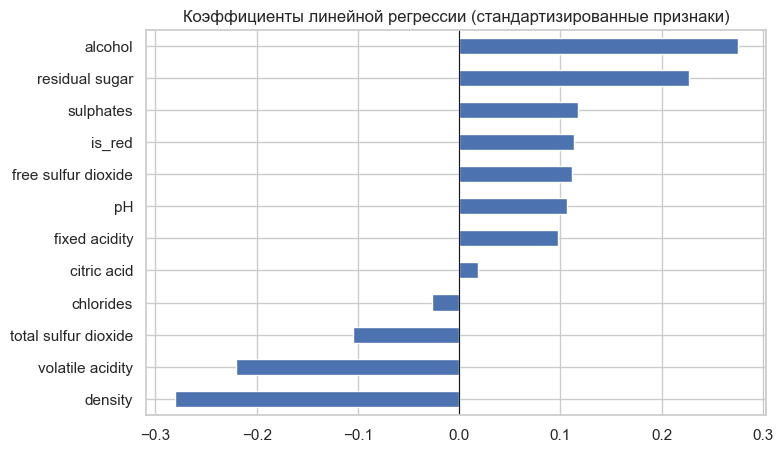

In [22]:
coef['coef_scaled'].sort_values().plot.barh(figsize=(8, 5), title='Коэффициенты линейной регрессии (стандартизированные признаки)')
plt.axvline(0, color='k', lw=0.8)
plt.show()

**Масштабирование и интерпретация.** Для качества предсказаний OLS-регрессии масштабирование не нужно (предсказания не меняются). Но «сырые» коэффициенты нельзя сравнивать между признаками: коэффициент при `density` (значения ≈ 1) и при `total sulfur dioxide` (значения в десятках и сотнях) относятся к совершенно разным единицам измерения. После стандартизации коэффициент показывает, на сколько баллов изменится `quality` при росте признака на одно стандартное отклонение, и признаки становятся сопоставимы по вкладу.

Из-за сильной корреляции между `density`, `alcohol` и `residual sugar` коэффициенты этих признаков могут быть завышены по модулю и компенсировать друг друга — это следствие мультиколлинеарности, а не обязательно реальное сильное влияние.

### 4.2 Random Forest

In [23]:
rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={'n_estimators': [300], 'max_features': [0.33, 0.5, 1.0], 'min_samples_leaf': [1, 2, 4]},
    cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
).fit(X_train, y_train)

rf = rf_grid.best_estimator_
cv_rmse['Random Forest'] = -rf_grid.best_score_
evaluate('Random Forest', rf.predict(X_test))
print(rf_grid.best_params_)
results['Random Forest']

{'max_features': 0.33, 'min_samples_leaf': 1, 'n_estimators': 300}


{'RMSE': np.float64(0.6798080178276488), 'MAE': 0.5256109022556391}

### 4.3 Gradient Boosting

In [27]:
gb_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_grid={'n_estimators': [300, 600], 'learning_rate': [0.05, 0.1], 'max_depth': [3, 5], 'subsample': [0.8]},
    cv=5, scoring='neg_root_mean_squared_error', n_jobs=-1
).fit(X_train, y_train)

gb = gb_grid.best_estimator_
cv_rmse['Gradient Boosting'] = -gb_grid.best_score_
evaluate('Gradient Boosting', gb.predict(X_test))
print(gb_grid.best_params_)
results['Gradient Boosting']

{'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 300, 'subsample': 0.8}


{'RMSE': np.float64(0.6892450742398959), 'MAE': 0.527635530022026}

## 5. Итоговое сравнение

In [28]:
res = pd.DataFrame(results).T[['RMSE', 'MAE']]
res['CV RMSE (train)'] = pd.Series(cv_rmse)
res['< baseline'] = res['RMSE'] < res.loc['Baseline', 'RMSE']
res['RMSE < 0.70'] = res['RMSE'] < 0.70
res.round(4)

,RMSE,MAE,CV RMSE (train),< baseline,RMSE < 0.70
Baseline,0.8801,0.6948,NaN,False,False
Linear Regression,0.7292,0.5660,0.7344,True,False
Random Forest,0.6798,0.5256,0.6863,True,True
Gradient Boosting,0.6892,0.5276,0.7001,True,True


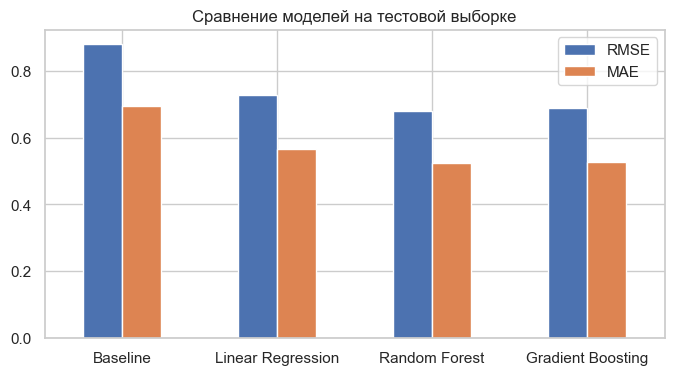

In [29]:
res[['RMSE', 'MAE']].plot.bar(figsize=(8, 4), rot=0, title='Сравнение моделей на тестовой выборке')
plt.show()

In [42]:
from sklearn.model_selection import KFold, cross_validate
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

kf = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    'Baseline': DummyRegressor(strategy='mean'),
    'Linear Regression': lr,
    'Random Forest': rf,
    'Gradient Boosting': gb
}

rows = []
for name, model in models.items():
    cv = cross_validate(
        model, X_train, y_train, cv=kf,
        scoring={'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error'},
    )
    rmse_cv, mae_cv = -cv['test_rmse'], -cv['test_mae']
    rows.append({
        'Модель': name,
        'CV RMSE': rmse_cv.mean(), 'RMSE std': rmse_cv.std(),
        'CV MAE': mae_cv.mean(), 'MAE std': mae_cv.std(),
    })

cv_table = pd.DataFrame(rows).set_index('Модель')
print(cv_table.round(4))

                   CV RMSE  RMSE std  CV MAE  MAE std
Модель                                               
Baseline            0.8796    0.0230  0.6949   0.0171
Linear Regression   0.7327    0.0202  0.5645   0.0152
Random Forest       0.6869    0.0175  0.5295   0.0118
Gradient Boosting   0.6972    0.0094  0.5383   0.0072


### Выводы по сравнению
- Baseline показывает, какое качество даёт предсказание без использования признаков; любая модель, не превосходящая его, не извлекает из данных пользовательской информации. Все обученные модели нужно сопоставить с ним по таблице выше (колонка `< baseline`).
- **Линейная регрессия** предполагает аддитивную линейную связь признаков с `quality`. Реальные зависимости в винах нелинейны и содержат взаимодействия (например, эффект кислотности зависит от сахара и типа вина), поэтому линейная модель ограничена по выразительности, а выбросы и мультиколлинеарность дополнительно ухудшают её.
- **Random Forest и Gradient Boosting** строят ансамбли деревьев, которые автоматически ловят нелинейности и взаимодействия признаков, не требуют масштабирования и устойчивы к выбросам и скошенности. Это, как правило, даёт заметное преимущество над линейной моделью на табличных данных такого типа.
- Различие между лесом и бустингом связано с тем, как строятся деревья: лес усредняет глубокие независимые деревья (снижает дисперсию), бустинг последовательно исправляет остатки (снижает смещение), но чувствителен к шуму в целевой переменной. Для данных с шумной субъективной оценкой разница между ними обычно небольшая и зависит от подбора гиперпараметров; ориентироваться нужно на сравнение CV RMSE и test RMSE в таблице.
- Часть дубликатов в данных может завышать качество деревьев, умеющих запоминать обучающие объекты (особенно случайный лес с глубокими деревьями).

## 6. Feature importance

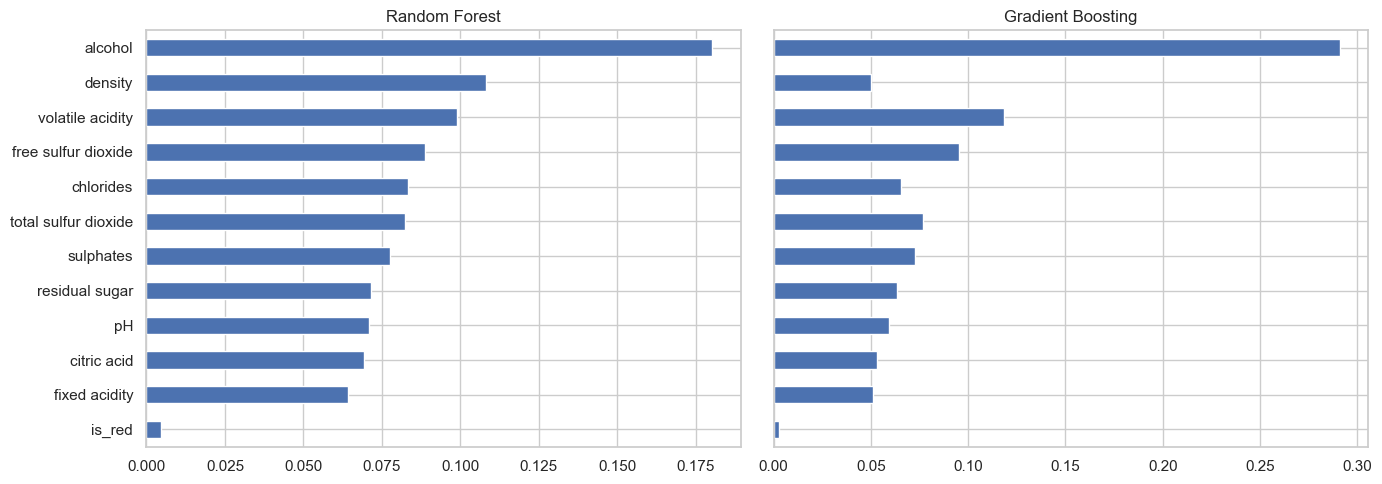

,Random Forest,Gradient Boosting
alcohol,0.1803,0.2909
density,0.1081,0.0502
volatile acidity,0.0991,0.1186
free sulfur dioxide,0.0888,0.0952
chlorides,0.0834,0.0654
total sulfur dioxide,0.0823,0.0768
sulphates,0.0776,0.0726
residual sugar,0.0714,0.0633
pH,0.0710,0.0596
citric acid,0.0694,0.0533


In [30]:
fi = pd.DataFrame({
    'Random Forest': rf.feature_importances_,
    'Gradient Boosting': gb.feature_importances_,
}, index=X.columns).sort_values('Random Forest', ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
fi['Random Forest'].sort_values().plot.barh(ax=ax[0], title='Random Forest')
fi['Gradient Boosting'].reindex(fi['Random Forest'].sort_values().index).plot.barh(ax=ax[1], title='Gradient Boosting')
plt.tight_layout()
plt.show()
fi.round(4)

### Выводы по важности признаков
- Таблица рангов позволяет сопоставить важность признаков по четырём источникам: корреляция в EDA, стандартизированные коэффициенты линейной модели, важность в случайном лесе и в бустинге. Признаки, которые стабильно в верхней части всех четырёх списков (как правило, `alcohol` и `volatile acidity`), можно считать наиболее надёжно связанными с оценкой.
- Расхождения объяснимы: линейная модель видит только линейный вклад «при прочих равных» и искажается мультиколлинеарностью; деревья ловят нелинейные эффекты и взаимодействия, поэтому могут поднять признаки, слабо коррелирующие с `quality` линейно (например, `free sulfur dioxide`). Impurity-based важность, кроме того, смещена в пользу признаков с большим числом уникальных значений.
- Лес и бустинг дают похожие, но не идентичные рейтинги: бустинг склонен концентрировать важность на нескольких сильных признаках, лес распределяет её более равномерно между коррелирующими признаками.

**Можно ли по feature importance утверждать, что признак является причиной изменения качества вина?** Нет. Feature importance показывает, насколько признак полезен модели для предсказания на имеющихся данных, то есть отражает ассоциацию, а не причинность. Признак может быть лишь индикатором скрытого фактора (например, `density` выступает прокси для содержания алкоголя и сахара), важность делится между коррелирующими признаками, а оценка `quality` — субъективная и зависит от дегустаторов. Для причинных выводов нужен эксперимент (например, контролируемое изменение одного параметра при прочих равных).

## 7. Анализ ошибок

Лучшая модель по CV на train: Random Forest


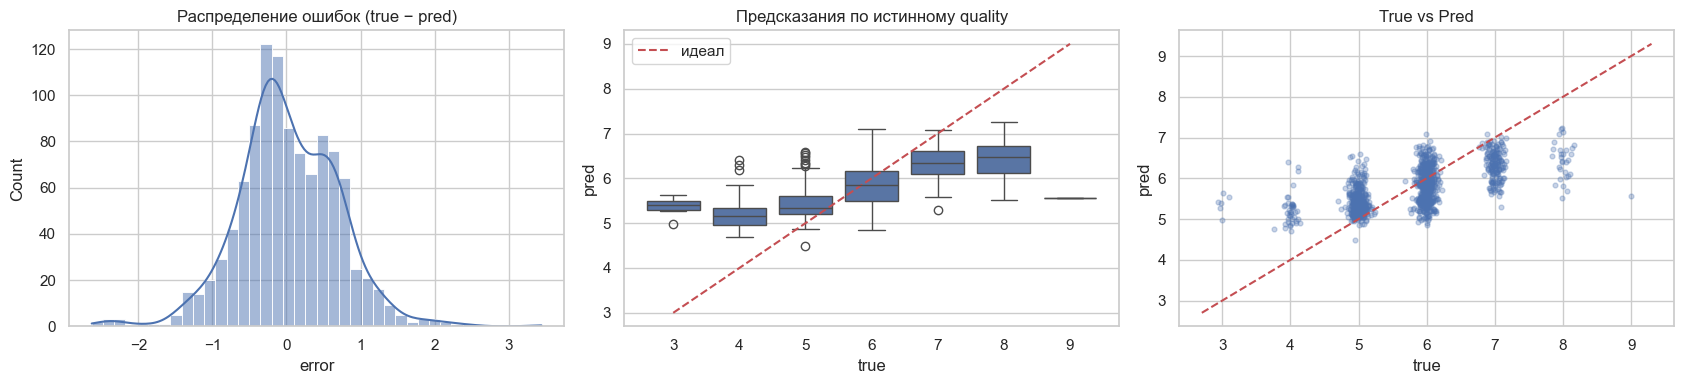

In [32]:
best_name = min(['Random Forest', 'Gradient Boosting'], key=lambda n: cv_rmse[n])
best_model = {'Random Forest': rf, 'Gradient Boosting': gb}[best_name]
print('Лучшая модель по CV на train:', best_name)

err = pd.DataFrame({'true': y_test.values, 'pred': best_model.predict(X_test)}, index=y_test.index)
err['error'] = err['true'] - err['pred']
err['abs_error'] = err['error'].abs()

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(err['error'], bins=40, kde=True, ax=ax[0])
ax[0].set_title('Распределение ошибок (true − pred)')
sns.boxplot(data=err, x='true', y='pred', ax=ax[1])
ax[1].plot(range(len(err['true'].unique())), sorted(err['true'].unique()), 'r--', label='идеал')
ax[1].set_title('Предсказания по истинному quality'); ax[1].legend()
ax[2].scatter(err['true'] + np.random.default_rng(0).normal(0, 0.08, len(err)), err['pred'], alpha=0.3, s=12)
lims = [err[['true', 'pred']].min().min() - 0.3, err[['true', 'pred']].max().max() + 0.3]
ax[2].plot(lims, lims, 'r--'); ax[2].set_xlabel('true'); ax[2].set_ylabel('pred'); ax[2].set_title('True vs Pred')
plt.tight_layout()
plt.show()

In [33]:
by_q = err.groupby('true').agg(
    n=('error', 'size'),
    MAE=('abs_error', 'mean'),
    RMSE=('error', lambda e: np.sqrt((e ** 2).mean())),
    mean_error=('error', 'mean'),
).round(3)
by_q

,n,MAE,RMSE,mean_error
true,,,,
3,6,2.368,2.377,-2.368
4,41,1.230,1.288,-1.230
5,350,0.433,0.538,-0.426
6,465,0.386,0.467,0.159
7,171,0.666,0.754,0.665
8,30,1.550,1.612,1.550
9,1,3.443,3.443,3.443


In [34]:
worst = err.sort_values('abs_error', ascending=False).head(10)
worst.join(X_test[['alcohol', 'volatile acidity', 'residual sugar', 'total sulfur dioxide', 'is_red']]).round(3)

,true,pred,error,abs_error,alcohol,volatile acidity,residual sugar,total sulfur dioxide,is_red
2373,9,5.557,3.443,3.443,10.4,0.270,10.60,124.0,0
2339,3,5.630,-2.630,2.630,12.6,0.390,4.60,19.0,0
1850,3,5.533,-2.533,2.533,9.8,0.260,16.20,197.0,0
3005,8,5.517,2.483,2.483,10.5,0.220,6.80,90.0,0
3287,3,5.417,-2.417,2.417,9.4,0.250,1.55,216.0,0
6107,4,6.407,-2.407,2.407,11.5,0.260,2.60,129.0,0
1374,3,5.383,-2.383,2.383,9.8,0.815,1.20,29.0,1
4668,8,5.700,2.300,2.300,12.5,0.530,6.10,76.0,0
5016,4,6.287,-2.287,2.287,12.9,0.640,1.20,76.0,0
1469,3,5.267,-2.267,2.267,9.7,0.980,2.10,49.0,1


### Выводы по ошибкам
- Распределение ошибок смотрится по гистограмме: оно должно быть примерно симметрично вокруг нуля, но с «хвостами» — именно они и определяют разрыв между RMSE и MAE.
- Таблица по значениям `quality` показывает систематическое смещение: у редких крайних оценок (3, 4 снизу и 8, 9 сверху) `mean_error` обычно существенно отличен от нуля. Для низких оценок модель завышает предсказание, для высоких — занижает. Причина в том, что модель минимизирует среднеквадратичную ошибку и поэтому тяготеет к плотной области 5–7, где сосредоточено большинство примеров; для редких классов обучающих объектов мало, и деревья не успевают выделить для них отдельные листья.
- На объектах с самыми крупными ошибками (таблица выше) обычно встречаются вина с «типичными» химическими характеристиками, но нетипичной оценкой: модель предсказывает значение около 5–6, а дегустаторы поставили крайнюю оценку. Возможные причины: субъективность и шум разметки (разные дегустаторы, органолептические свойства, не отражённые в физико-химических признаках — аромат, вкус), нетипичные значения признаков (выбросы) и малое количество похожих примеров в обучающей выборке.
- Итоговое RMSE следует интерпретировать с учётом того, что на основной массе объектов модель работает заметно лучше, чем на редких классах.

## 8. Итог

In [35]:
beat = res.index[(res['< baseline']) & (res.index != 'Baseline')].tolist()
print('Модели лучше baseline:', beat)
print('Модели с RMSE < 0.70:', res.index[res['RMSE < 0.70']].tolist())
print('Лучшая по test RMSE:', res['RMSE'].idxmin(), round(res['RMSE'].min(), 4))

Модели лучше baseline: ['Linear Regression', 'Random Forest', 'Gradient Boosting']
Модели с RMSE < 0.70: ['Random Forest', 'Gradient Boosting']
Лучшая по test RMSE: Random Forest 0.6798
